In [5]:
import sys
# sys.path.append('src')
sys.path.append('../../paste3/src')
sys.path.append('../../paste3/src/paste3')
from align import *
from glmpca import *
from helper import *
from model_selection import *
from paste import *
from visualization import *
import anndata as ad
import scanpy as sc
from sampler_full import fused_tlb, full_fgw, eval_pair, fused_upper_bounds
import time
from scipy.stats import spearmanr
from scipy.spatial.distance import cdist, pdist

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path

DIR = Path("../../Data/FLYSTA")

CONFIG = [
    (12.94, "12.94h_E10-12h_f_new_final_modified.h5ad"),
    (13.26, "13.26h_E10-12h_e_new_final_modified.h5ad"),
    (13.79, "13.79h_E10-12h_d_new_final_modified.h5ad"),
]

timepoints = [t for t, _ in CONFIG]
tp_data = {}

for t, filename in CONFIG:
    a = sc.read_h5ad(DIR / filename)

    if not a.var_names.is_unique:
        raise ValueError(f"{filename}: duplicate gene names")
    if "spatial" not in a.obsm:
        raise ValueError(f"{filename}: missing spatial coordinates")

    # Use downloaded .X and spatial coordinates unchanged.
    # No cropping, normalization, log1p, HVG selection, or spot filtering.
    a.obs["slices"] = a.obs["slices"].astype(str)
    a.obs["time"] = t
    a.obs["section"] = (
        str(t) + "_" + a.obs["slices"]
    ).astype("category")

    tp_data[t] = a

    print(
        f"{t} h: {a.n_obs:,} spots, {a.n_vars:,} genes, "
        f"{a.obs['slices'].nunique()} sections"
    )


def sub(A, s):
    return A[A.obs["slices"] == s].copy()


def slices_of(A):
    return sorted(A.obs["slices"].astype(str).unique())


def n_of(A, s):
    return int((A.obs["slices"] == s).sum())


# For existing visualization cells only.
# All distance calculations use tp_data, not this concatenated matrix.
adata = sc.concat(
    [tp_data[t] for t in timepoints],
    join="outer",
)
adata.obs_names_make_unique()

zmap = {
    t: tp_data[t].obs.groupby(
        "slices", observed=True
    )["align_z"].median()
    for t in timepoints
}

12.94 h: 32,418 spots, 9,815 genes, 23 sections
13.26 h: 31,308 spots, 9,535 genes, 21 sections
13.79 h: 31,079 spots, 9,474 genes, 22 sections


## Visualize the slices

/tmp/ipykernel_1834303/757391218.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  z = np.array([tp_data[t][ tp_data[t].obs['slices']==s ].obs['align_z'][0] for s in secs])


[168. 182. 196. 210. 224. 238. 252. 266. 280. 294. 308. 336. 350. 364.
 378. 392. 406. 434. 448. 476. 490. 504. 518.]
[126. 154. 168. 196. 210. 224. 238. 252. 266. 280. 294. 308. 322. 336.
 350. 364. 378. 392. 406. 420. 434.]
[126. 140. 154. 168. 182. 196. 210. 224. 238. 252. 266. 280. 294. 308.
 322. 336. 350. 364. 378. 392. 406. 420.]


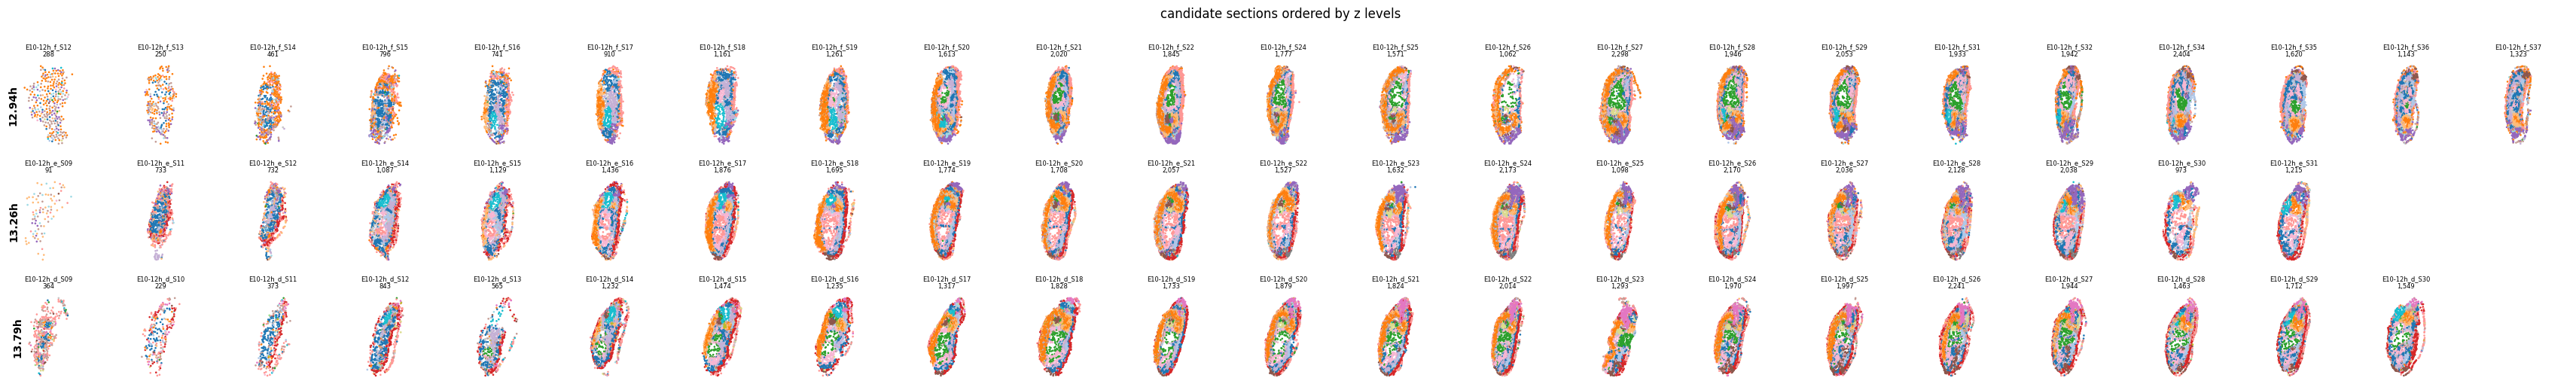

In [7]:
import numpy as np, matplotlib.pyplot as plt

from scipy.spatial import ConvexHull
rng = np.random.default_rng(0)

LABEL = 'Annotation_1_cell_type'
cats  = sorted(adata.obs[LABEL].astype(str).unique())
pal   = {c: plt.cm.tab20(i % 20) for i, c in enumerate(cats)}

def sub(A, s): return A[A.obs['slices'] == s]
def slices_of(A): return sorted(A.obs['slices'].unique())
def n_of(A, s): return sub(A, s).n_obs

t = timepoints[0]
secs = sorted(slices_of(tp_data[t]), key=lambda s: zmap[t][s])



# sections per timepoint, ordered by Isomap coordinate
ordered = {}
for t in timepoints:
    secs = slices_of(tp_data[t])
    # z    = np.array([tp_data[t][ tp_data[t].obs['slices']==s ].shape[0] for s in secs])
    z = np.array([tp_data[t][ tp_data[t].obs['slices']==s ].obs['align_z'][0] for s in secs])
    print(z)
    ordered[t] = [secs[i] for i in np.argsort(z)]

ncol = max(len(v) for v in ordered.values())
fig, axs = plt.subplots(len(timepoints), ncol,
                        figsize=(1.5 * ncol, 1.7 * len(timepoints)), squeeze=False)
for ax in axs.ravel():
    ax.axis('off')

for r, t in enumerate(timepoints):
    for c, s in enumerate(ordered[t]):
        A  = sub(tp_data[t], s)
        xy = np.asarray(A.obsm['spatial'], float)
        ax = axs[r, c]
        ax.scatter(xy[:, 0], xy[:, 1], s=0.8,
                   c=[pal[v] for v in A.obs[LABEL].astype(str)])
        ax.set_title(f"{s}\n{A.n_obs:,}", fontsize=6)
        ax.set_aspect('equal'); ax.invert_yaxis(); ax.axis('off')
    axs[r, 0].axis('on')
    axs[r, 0].set_xticks([]); axs[r, 0].set_yticks([])
    for sp in axs[r, 0].spines.values():
        sp.set_visible(False)
    axs[r, 0].set_ylabel(f"{t}h", fontsize=10, fontweight='bold', rotation=90)

fig.suptitle("candidate sections ordered by z levels", y=1.0)
fig.tight_layout()
plt.show()

## For fair comparison of distances later, we choose a universal scale

In [8]:
from scipy.spatial.distance import cdist


def positive_median(M, name):
    values = M[np.isfinite(M) & (M > 0)]
    if values.size == 0:
        raise ValueError(f"No positive finite distances for {name}")
    return float(np.median(values))


# Largest section across all three embryos.

candidates = [
    (n_of(tp_data[t], s), t, s)
    for t in timepoints
    for s in slices_of(tp_data[t])
]

reference_spots, reference_time, reference_section = sorted(
    candidates,
    key=lambda v: (-v[0], v[1], v[2]),
)[0]

reference = sub(tp_data[reference_time], reference_section)

# Feature scale: median positive expression distance within reference.
X_ref = to_dense_array(reference.X).double()
M_ref = dissimilarity_metric(
    "euc", reference, reference, X_ref, X_ref
).cpu().numpy()
np.fill_diagonal(M_ref, 0)

FEAT_SCALE = positive_median(M_ref, "expression scale")

# Spatial scale: median positive spatial distance within reference.
xy_ref = np.asarray(reference.obsm["spatial"], dtype=float)
D_ref = cdist(xy_ref, xy_ref)
np.fill_diagonal(D_ref, 0)

SPATIAL_SCALE = positive_median(D_ref, "spatial scale")

# Retain all spots in every section.
MAX_SPOTS = max(n for n, _, _ in candidates)

BASE_ARGS = dict(
    alpha=0.5,
    exp_metric="euclidean",
    feat_scale=FEAT_SCALE,
    spatial_scale=SPATIAL_SCALE,
    solver="ott",
    max_spots=MAX_SPOTS,
    seed=0,
)
ARGS = dict(BASE_ARGS)

In [9]:
import time
import pickle
import numpy as np
from scipy.stats import spearmanr

ARGS = dict(BASE_ARGS)


def sub(A, s):
    return A[A.obs["slices"] == s].copy()


def slices_of(A):
    return sorted(A.obs["slices"].astype(str).unique())


def n_of(A, s):
    return int((A.obs["slices"] == s).sum())


cost_tensors, feat_tensors, strc_tensors = {}, {}, {}
timing_rows = []

for ta, tb in zip(timepoints, timepoints[1:]):
    A, B = tp_data[ta], tp_data[tb]
    sa, sb = slices_of(A), slices_of(B)

    C = np.zeros((len(sa), len(sb)))
    Cf = np.zeros_like(C)
    Cs = np.zeros_like(C)

    transition_start = time.perf_counter()
    total_pairs = len(sa) * len(sb)

    for i, a in enumerate(sa):
        Aa = sub(A, a)

        for j, b in enumerate(sb):
            pair_number = i * len(sb) + j + 1
            print(
                f"[{pair_number}/{total_pairs}] "
                f"{ta}->{tb}  {a} -> {b} ...",
                end=" ",
                flush=True,
            )

            pair_start = time.perf_counter()

            # Same settings as the within-embryo pipeline:
            # shared reference scales, all spots, no explicit K override.
            val, feat, strc = fused_tlb(
                Aa, sub(B, b), **ARGS
            )

            C[i, j] = float(val)
            Cf[i, j] = float(feat)
            Cs[i, j] = float(strc)

            if not np.isfinite(
                [C[i, j], Cf[i, j], Cs[i, j]]
            ).all():
                raise ValueError(
                    f"Nonfinite result: {ta}/{a} -> {tb}/{b}"
                )

            seconds = time.perf_counter() - pair_start
            timing_rows.append({
                "source_embryo": ta,
                "target_embryo": tb,
                "source_section": a,
                "target_section": b,
                "lb_seconds": seconds,
            })

            print(
                f"{C[i, j]:.6g}  ({seconds:.2f}s)",
                flush=True,
            )

    cost_tensors[(ta, tb)] = (C, sa, sb)
    feat_tensors[(ta, tb)] = Cf
    strc_tensors[(ta, tb)] = Cs

    elapsed = time.perf_counter() - transition_start

    print(f"\n{ta} h -> {tb} h")
    print(
        f"{len(sa)} x {len(sb)} sections; "
        f"elapsed {elapsed / 60:.2f} min"
    )
    print(f"Source sections: {[(s, n_of(A, s)) for s in sa]}")
    print(f"Target sections: {[(s, n_of(B, s)) for s in sb]}")
    print("fTLB cost matrix:")
    print(np.array2string(C, precision=3))
    print(
        f"Cost range: [{C.min():.3f}, {C.max():.3f}]; "
        f"any negative: {bool((C < 0).any())}"
    )
    print(
        f"Mean feature contribution: {Cf.mean():.3f}; "
        f"mean structural contribution: {Cs.mean():.3f}"
    )

    na = np.array([n_of(A, s) for s in sa])
    nb = np.array([n_of(B, s) for s in sb])
    ndiff = np.abs(na[:, None] - nb[None, :])

    if C.size > 3 and np.ptp(C) > 0 and np.ptp(ndiff) > 0:
        rho = spearmanr(C.ravel(), ndiff.ravel()).statistic
        print(f"Cost vs |Δspot-count| Spearman: {rho:+.3f}")

    # Save completed transitions as the computation progresses.
    with open("flysta_cost_tensors_lower.pkl", "wb") as f:
        pickle.dump(cost_tensors, f)

    with open("flysta_cost_components_lower.pkl", "wb") as f:
        pickle.dump({
            "feature": feat_tensors,
            "structural": strc_tensors,
        }, f)

    pd.DataFrame(timing_rows).to_csv(
        "flysta_lower_times.csv", index=False
    )

print(f"\nAll {len(cost_tensors)} transitions completed.")

[1/483] 12.94->13.26  E10-12h_f_S12 -> E10-12h_e_S09 ... (ERROR) (xla_bridge.py) (04-Nov-26 04:56:10) Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/home/zhaow/miniforge3/lib/python3.13/site-packages/jax/_src/xla_bridge.py", line 495, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/home/zhaow/miniforge3/lib/python3.13/site-packages/jax_plugins/xla_cuda13/__init__.py", line 370, in initialize
    _check_cuda_versions(raise_on_first_error = True)
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/zhaow/miniforge3/lib/python3.13/site-packages/jax_plugins/xla_cuda13/__init__.py", line 274, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
                   ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:135: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName faile

## Now, compute outer OT coupling

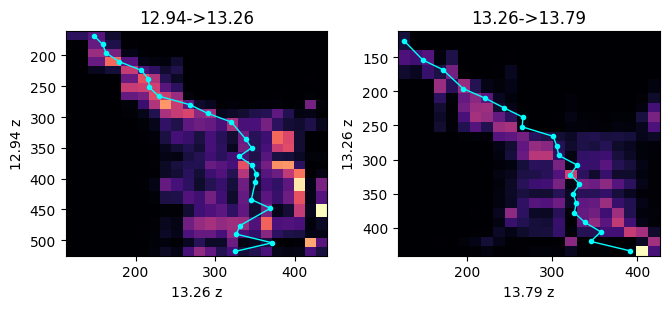

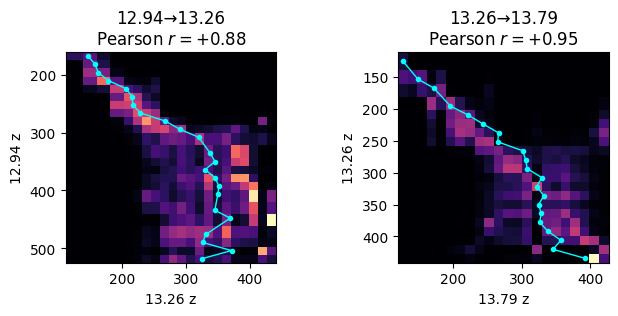

In [10]:
import numpy as np, ot

def ot_couplings(cost_tensors, timepoints, section_mass,
                 reg_frac=0.01, alpha=1.0):
    """
    section_mass : dict {section_name: tissue spot count or occupied area}
    alpha=1.0    : area-proportional marginals
    alpha=0.5    : softened sqrt-area marginals
    alpha=0.0    : uniform section marginals
    """
    Gs = {}

    for ta, tb in zip(timepoints, timepoints[1:]):
        C, sa, sb = cost_tensors[(ta, tb)]

        wa = np.asarray([section_mass[s] for s in sa], dtype=float) ** alpha
        wb = np.asarray([section_mass[s] for s in sb], dtype=float) ** alpha

        p = wa / wa.sum()
        q = wb / wb.sum()
        C = C / max(C.max(), 1e-9)
        reg = reg_frac# * max(C.max(), 1e-9)
        G = ot.sinkhorn(p, q, C, reg=reg)

        Gs[(ta, tb)] = (G, sa, sb)

    return Gs
 


section_mass = adata.obs.groupby("slices", observed=True).size().to_dict()

Gs = ot_couplings(
    cost_tensors,
    timepoints,
    section_mass=section_mass,
    alpha=1.0,
)
 
## Visualize the depth between connected slices
 

zmap = {t: tp_data[t].obs.groupby('slices', observed=True)['align_z'].first() for t in timepoints}

fig, axs = plt.subplots(1, len(Gs), figsize=(3.4*len(Gs), 3.2), squeeze=False)
for ax, ((ta, tb), (G, sa, sb)) in zip(axs[0], Gs.items()):
    za, zb = zmap[ta][list(sa)].values, zmap[tb][list(sb)].values
    oa, ob = np.argsort(za), np.argsort(zb)
    Gz = G[np.ix_(oa, ob)]
    mu = (Gz / Gz.sum(1, keepdims=True)) @ zb[ob]

    ax.pcolormesh(zb[ob], za[oa], Gz, cmap='magma')
    ax.plot(mu, za[oa], '-o', c='cyan', lw=1, ms=3)
    ax.set(xlabel=f"{tb} z", ylabel=f"{ta} z", title=f"{ta}->{tb}")
    ax.invert_yaxis()
plt.tight_layout(); plt.show()

from scipy.stats import pearsonr

fig, axs = plt.subplots(
    1, len(Gs), figsize=(3.4 * len(Gs), 3.2), squeeze=False
)

for ax, ((ta, tb), (G, sa, sb)) in zip(axs[0], Gs.items()):
    za = zmap[ta][list(sa)].values
    zb = zmap[tb][list(sb)].values

    oa, ob = np.argsort(za), np.argsort(zb)
    Gz = G[np.ix_(oa, ob)]

    Pz = Gz / np.maximum(Gz.sum(axis=1, keepdims=True), 1e-30)
    mu = Pz @ zb[ob]

    r = pearsonr(za[oa], mu).statistic

    ax.pcolormesh(zb[ob], za[oa], Gz, cmap="magma")
    ax.plot(mu, za[oa], "-o", c="cyan", lw=1, ms=3)
    ax.set(
        xlabel=f"{tb} z",
        ylabel=f"{ta} z",
        title=f"{ta}→{tb}\nPearson $r={r:+.2f}$",
    )
    ax.set_box_aspect(1)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

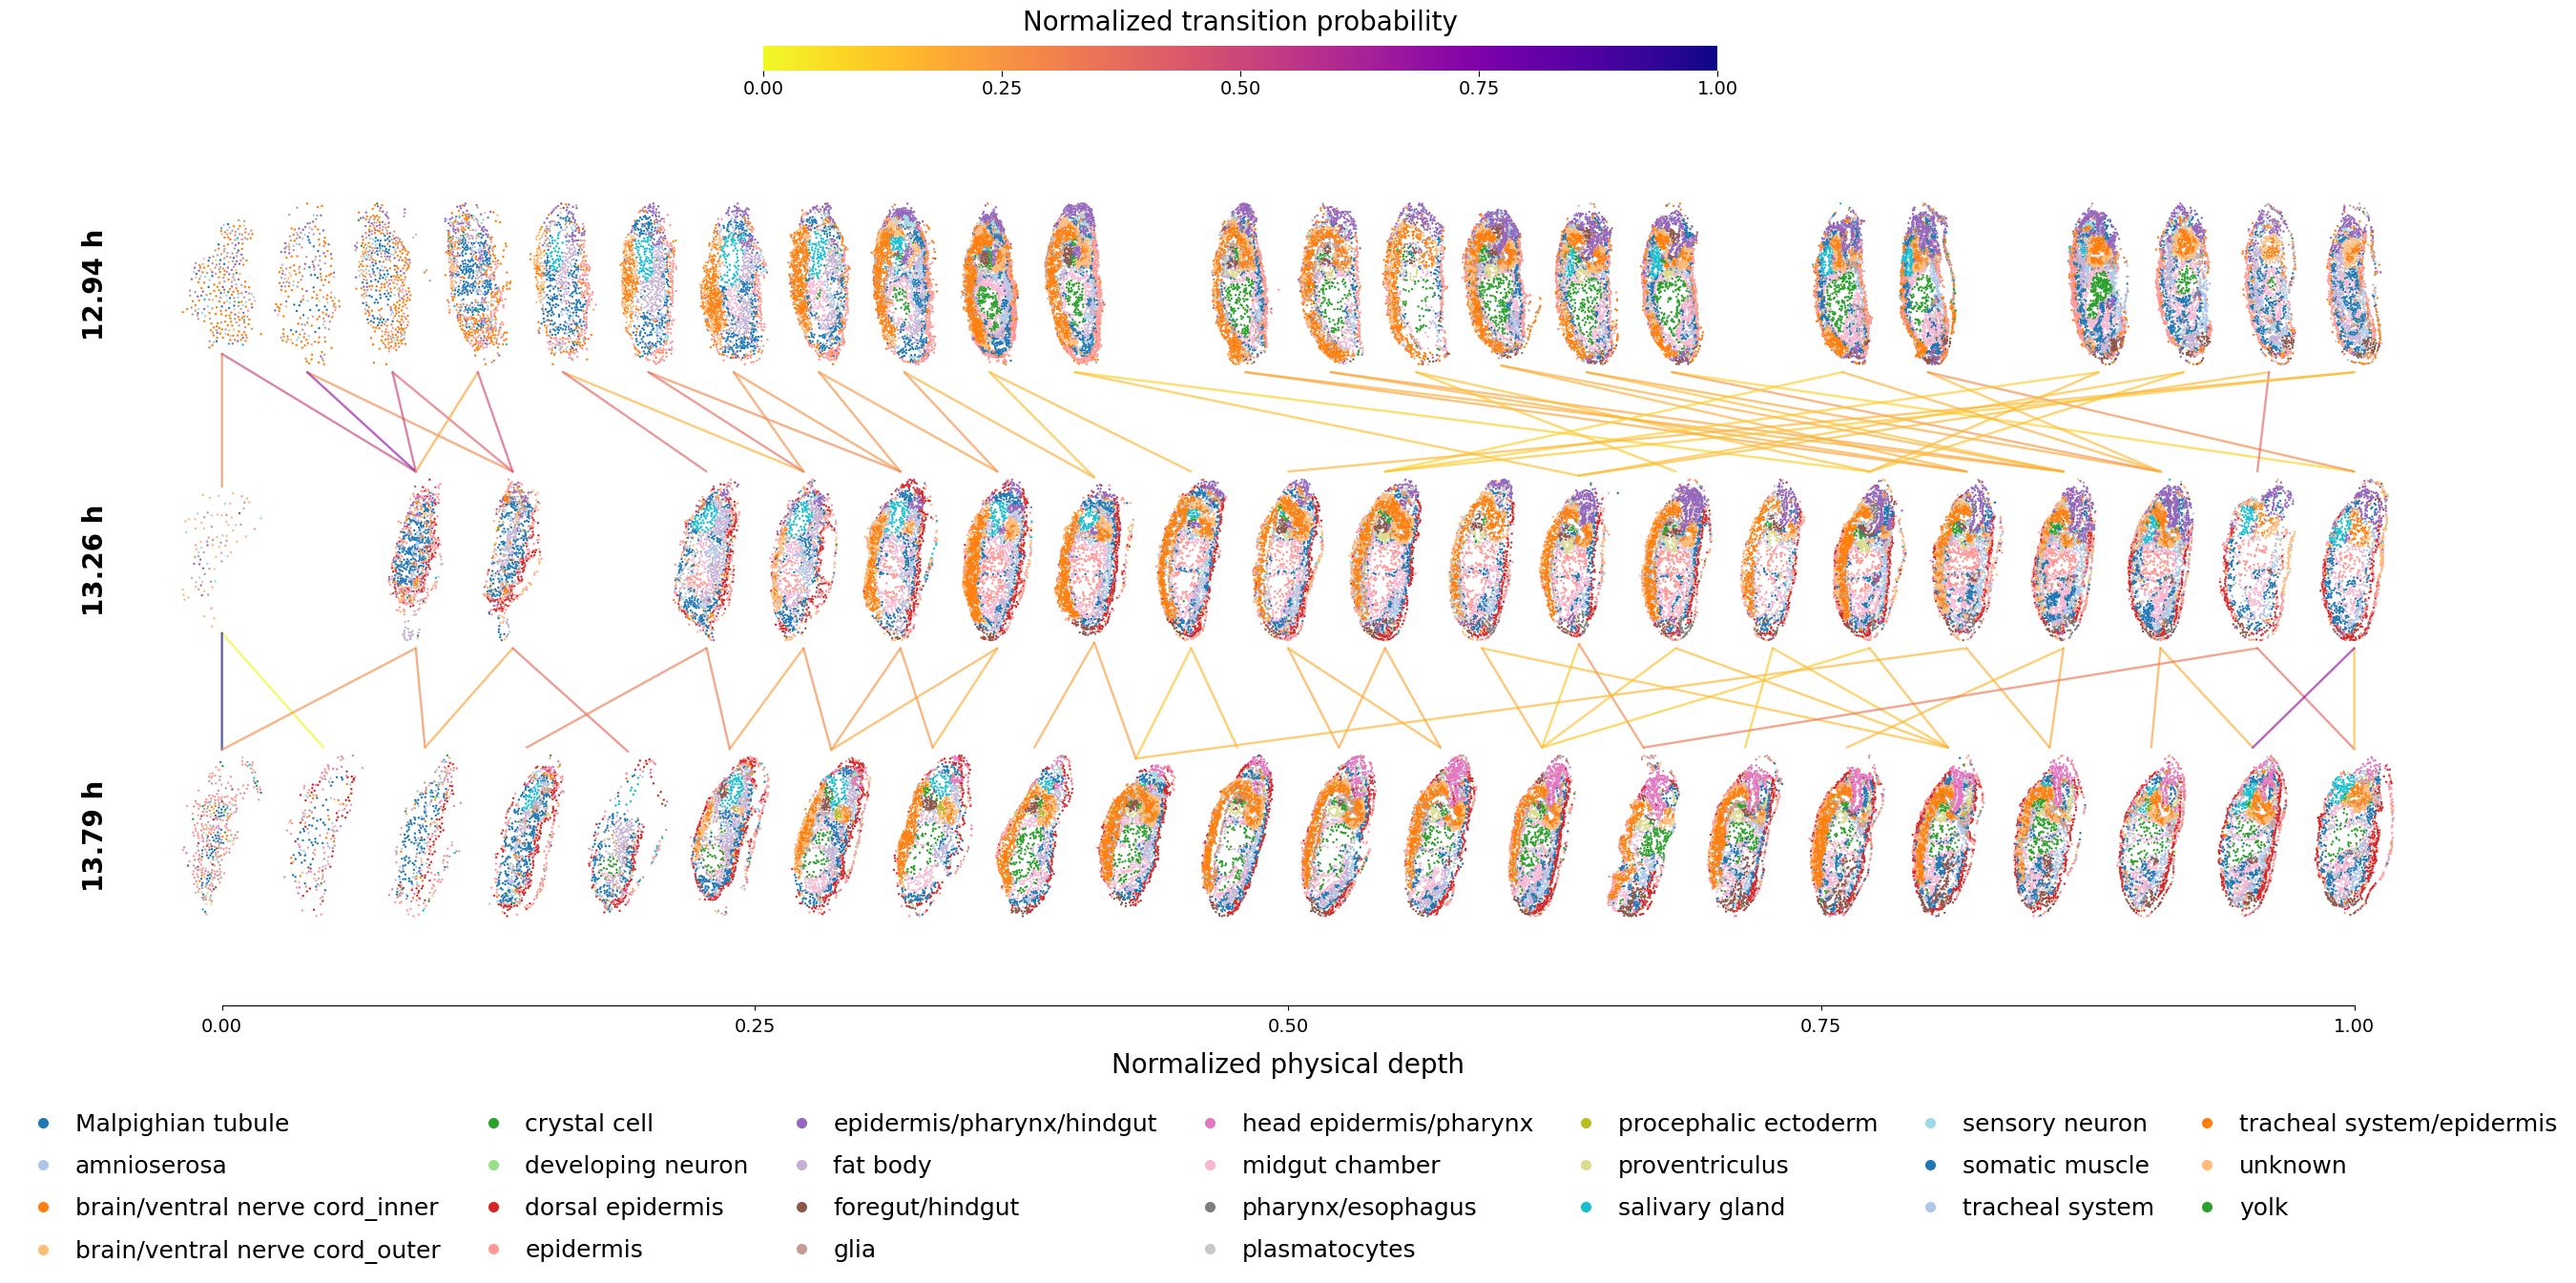

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import ConnectionPatch
from matplotlib.lines import Line2D

# ---------------- Layout ----------------
R = len(timepoints)

FIG_WIDTH = 25
FIG_HEIGHT = 3.0 * R + 5.0

LEFT, RIGHT = 0.055, 0.985
TOP, BOTTOM = 0.86, 0.24

ROW_HEIGHT = (TOP - BOTTOM) / R
SECTION_HEIGHT = ROW_HEIGHT * 0.64
SECTION_WIDTH = 0.036

FONT = 20
ROW_FONT = 20
LEGEND_FONT = 18

cmap = plt.cm.plasma_r
norm = mpl.colors.Normalize(vmin=0, vmax=1)

fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT))
axd = {}

# ---------------- Normalize physical z within each embryo ----------------
# No absolute value, folding, or estimated midline.
normalized_z = {}

for t in timepoints:
    z = (
        tp_data[t].obs.groupby("slices", observed=True)["align_z"]
        .median()
    )

    if not np.isfinite(z.to_numpy(dtype=float)).all():
        raise ValueError(f"{t} h: nonfinite physical depths")

    span = z.max() - z.min()
    normalized_z[t] = (
        (z - z.min()) / span if span > 0 else z * 0
    )

# ---------------- Section thumbnails ----------------
for r, t in enumerate(timepoints):
    secs = sorted(
        slices_of(tp_data[t]),
        key=lambda s: (float(normalized_z[t].loc[s]), str(s)),
    )
    u = np.array(
        [normalized_z[t].loc[s] for s in secs],
        dtype=float,
    )

    row_bottom = TOP - (r + 1) * ROW_HEIGHT
    ybot = row_bottom + 0.22 * ROW_HEIGHT

    fig.text(
        0.020,
        ybot + SECTION_HEIGHT / 2,
        f"{t:.2f} h",
        rotation=90,
        ha="center",
        va="center",
        fontsize=ROW_FONT,
        fontweight="bold",
    )

    for s, position in zip(secs, u):
        xleft = LEFT + position * (
            RIGHT - LEFT - SECTION_WIDTH
        )

        ax = fig.add_axes([
            xleft,
            ybot,
            SECTION_WIDTH,
            SECTION_HEIGHT,
        ])

        A = sub(tp_data[t], s)

        # Registered coordinates for display, when available.
        spatial_key = (
            "align_spatial"
            if "align_spatial" in A.obsm
            else "spatial"
        )
        xy = np.asarray(A.obsm[spatial_key], dtype=float)

        # Retain your original thumbnail display orientation.
        yy = -xy[:, 1] if r == 0 else xy[:, 1]

        ax.scatter(
            xy[:, 0],
            yy,
            s=3.0,
            c=[pal[v] for v in A.obs[LABEL].astype(str)],
            alpha=1.0,
            linewidths=0,
            rasterized=True,
        )
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")

        axd[(t, s)] = ax

# ---------------- Coupling connections ----------------
# Show the two largest outgoing probabilities per source section.
for ta, tb in zip(timepoints, timepoints[1:]):
    G, sa, sb = Gs[(ta, tb)]
    G = G.toarray() if hasattr(G, "toarray") else np.asarray(G)
    G = G.astype(float, copy=False)

    row_mass = G.sum(axis=1, keepdims=True)
    P = np.divide(
        G,
        row_mass,
        out=np.zeros_like(G),
        where=row_mass > 0,
    )

    for i, s in enumerate(sa):
        top_targets = np.argsort(P[i])[-min(2, len(sb)):]

        for j in top_targets:
            probability = float(P[i, j])
            if probability < 0.001:
                continue

            fig.add_artist(ConnectionPatch(
                xyA=(0.5, 0),
                coordsA=axd[(ta, s)].transAxes,
                xyB=(0.5, 1),
                coordsB=axd[(tb, sb[j])].transAxes,
                linewidth=1.7,
                color=cmap(norm(probability)),
                alpha=0.65,
                clip_on=False,
                zorder=0,
            ))

# ---------------- Color bar ----------------
cb_ax = fig.add_axes([0.30, 0.925, 0.40, 0.018])

colorbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cb_ax,
    orientation="horizontal",
)
colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
colorbar.ax.tick_params(labelsize=14, length=4)
colorbar.outline.set_visible(False)
colorbar.ax.set_title(
    "Normalized transition probability",
    fontsize=FONT,
    pad=12,
)

# ---------------- Physical depth axis ----------------
axis_left = LEFT + SECTION_WIDTH / 2
axis_right = RIGHT - SECTION_WIDTH / 2

depth_ax = fig.add_axes([
    axis_left,
    BOTTOM - 0.015,
    axis_right - axis_left,
    0.001,
])
depth_ax.set_xlim(0, 1)
depth_ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
depth_ax.set_yticks([])
depth_ax.tick_params(axis="x", labelsize=14, pad=6)

for side in ["left", "right", "top"]:
    depth_ax.spines[side].set_visible(False)

depth_ax.set_xlabel(
    "Normalized physical depth",
    fontsize=FONT,
    labelpad=12,
)

# ---------------- Cell-type legend ----------------
handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=pal[c],
        markeredgecolor="none",
        markersize=8,
        label=c,
    )
    for c in sorted(pal)
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.52, 0.015),
    ncol=7,
    frameon=False,
    fontsize=LEGEND_FONT,
    columnspacing=1.2,
    handletextpad=0.35,
    labelspacing=0.8,
)

plt.show()

In [12]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

rng = np.random.default_rng(0)
N = 30

sections = {t: sorted(slices_of(tp_data[t])) for t in timepoints}
qmap = {t: zmap[t].rank(method='average', pct=True) for t in timepoints}

def sample_path(Gs, timepoints, rng):
    G, sa, sb = Gs[(timepoints[0], timepoints[1])]
    p = G.sum(1)
    path = {timepoints[0]: sa[rng.choice(len(sa), p=p / p.sum())]}
    for ta, tb in zip(timepoints, timepoints[1:]):
        G, sa, sb = Gs[(ta, tb)]
        row = G[list(sa).index(path[ta])]
        path[tb] = sb[rng.choice(len(sb), p=row / row.sum())]
    return path

def depth_path(timepoints, qmap, rng):
    t0 = timepoints[0]
    s0 = rng.choice(qmap[t0].index)
    q = qmap[t0].loc[s0]
    return {t: (qmap[t] - q).abs().idxmin() for t in timepoints}

trajs = {}
trajs.update({f'ours{r}': sample_path(Gs, timepoints, rng) for r in range(N)})
trajs.update({f'rand{r}': {t: rng.choice(sections[t]) for t in timepoints}
              for r in range(N)})
trajs.update({f'depth{r}': depth_path(timepoints, qmap, rng) for r in range(N)})

memo, rows = {}, []
t0 = time.perf_counter()

for ta, tb in zip(timepoints, timepoints[1:]):
    for name, traj in trajs.items():
        a, b = traj[ta], traj[tb]
        k = (ta, a, tb, b)

        if k not in memo:
            print(f"  {ta}->{tb} {name:8s} {a} -> {b} ...", end=' ', flush=True)
            tic = time.perf_counter()
            memo[k] = eval_pair(
                sub(tp_data[ta], a),
                sub(tp_data[tb], b),
                k,
                annotation=LABEL,
                **ARGS
            )
            print(
                f"ami={memo[k][1]:.3f} mig={memo[k][0]:.3f} "
                f"idn={memo[k][2]:.3f} "
                f"({time.perf_counter()-tic:.1f}s)",
                flush=True
            )

        mig, ami, idn = memo[k]
        group = (
            'ours' if name.startswith('ours')
            else 'random' if name.startswith('rand')
            else 'depth'
        )

        rows.append(dict(
            trans=f"{ta}->{tb}",
            path=name,
            group=group,
            ami=ami,
            mig=mig,
            idn=idn
        ))

print(f"{len(memo)} pairs evaluated in {time.perf_counter()-t0:.1f}s")

df = pd.DataFrame(rows)
summ = df.copy()

order = ['random', 'ours', 'depth']
transitions = [f"{a}->{b}" for a, b in zip(timepoints[:-1], timepoints[1:])]

fig, axs = plt.subplots(len(transitions), 3,
                        figsize=(13, 4 * len(transitions)),
                        squeeze=False)

for r, trans in enumerate(transitions):
    d = summ[summ.trans == trans]

    for ax, (m, alt) in zip(
        axs[r],
        [('ami', 'greater'), ('mig', 'less'), ('idn', 'greater')]
    ):
        for i, g in enumerate(order):
            v = d.loc[d.group == g, m].values
            ax.boxplot(v, positions=[i], widths=.5, showfliers=False)
            ax.scatter(i + rng.normal(0, .05, len(v)), v, s=35, zorder=3)

        a = d.loc[d.group == 'ours', m].values
        b = d.loc[d.group == 'random', m].values
        U, p = mannwhitneyu(a, b, alternative=alt)
        rb = 2 * U / (len(a) * len(b)) - 1

        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order)
        ax.set_title(f"{trans}: {m}\np={p:.3g}, rb={rb:+.2f}")

plt.tight_layout()
plt.show()

print(summ.round(3).to_string(index=False))
print(
    summ.groupby('group')[['ami', 'mig', 'idn']]
        .agg(['mean', 'std'])
        .round(3)
)

  12.94->13.26 ours0    E10-12h_f_S29 -> E10-12h_e_S22 ... ami=0.144 mig=0.265 idn=0.124 (20.9s)
  12.94->13.26 ours1    E10-12h_f_S13 -> E10-12h_e_S12 ... ami=0.098 mig=0.507 idn=0.062 (4.6s)
  12.94->13.26 ours2    E10-12h_f_S28 -> E10-12h_e_S28 ... ami=0.155 mig=0.239 idn=0.152 (23.0s)
  12.94->13.26 ours3    E10-12h_f_S36 -> E10-12h_e_S30 ... ami=0.176 mig=0.325 idn=0.170 (6.6s)
  12.94->13.26 ours4    E10-12h_f_S34 -> E10-12h_e_S19 ... ami=0.152 mig=0.303 idn=0.119 (25.2s)
  12.94->13.26 ours5    E10-12h_f_S19 -> E10-12h_e_S18 ... ami=0.201 mig=0.291 idn=0.186 (12.8s)
  12.94->13.26 ours6    E10-12h_f_S22 -> E10-12h_e_S22 ... ami=0.227 mig=0.257 idn=0.205 (13.4s)
  12.94->13.26 ours7    E10-12h_f_S18 -> E10-12h_e_S16 ... ami=0.242 mig=0.331 idn=0.232 (13.6s)
  12.94->13.26 ours8    E10-12h_f_S28 -> E10-12h_e_S24 ... ami=0.219 mig=0.202 idn=0.212 (23.0s)
  12.94->13.26 ours9    E10-12h_f_S37 -> E10-12h_e_S25 ... ami=0.103 mig=0.293 idn=0.108 (10.7s)
  12.94->13.26 ours10   E10-12h_